In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from pyampute.exploration.mcar_statistical_tests import MCARTest

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer 

RANDOM_STATE = 67
np.random.seed(RANDOM_STATE)

In [151]:
df = pd.read_csv("/home/bhavana/SEM-III/DCV-Project-2026/data/raw/budget_nfhs_states.csv")
print("Shape of DataFrame :", df.shape)
df.head(5)

Shape of DataFrame : (29, 47)


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Neonatal mortality rate (NNMR),Infant mortality rate (IMR),Under-five mortality rate (U5MR),Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),Average out-of-pocket expenditure per delivery in a public health facility (Rs.),...,Children under 5 years who are underweight (weight-for-age)18 (%),Children under 5 years who are overweight (weight-for-height)20 (%),Women whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2)21 (%),Men whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2) (%),Women who are overweight or obese (BMI ≥25.0 kg/m2)21 (%),Men who are overweight or obese (BMI ≥25.0 kg/m2) (%),Women age 15 years and above who use any kind of tobacco (%),Men age 15 years and above who use any kind of tobacco (%),Women age 15 years and above who consume alcohol (%),Men age 15 years and above who consume alcohol (%)
0,Andhra Pradesh,"5,25,04,000","5,25,929.60",605549.45,526323.02,14.4,29.8,33.7,92.2,2659,...,25.1,3.0,11.9,15.0,44.4,37.7,1.9,15.8,0.3,20.5
1,Arunachal Pradesh,"15,19,000",92615,131266.59,91612.2,12.5,16.7,22.2,67.0,10178,...,13.1,9.6,5.6,6.4,28.9,32.4,14.0,44.5,14.9,44.3
2,Assam,"3,46,68,000",451977.3,591193.62,633180.84,15.2,22.7,33.0,76.8,6651,...,25.9,8.0,13.9,11.3,23.8,25.4,16.2,43.9,2.6,21.3
3,Bihar,"12,13,02,000",611797.7,"6,38,425.20","7,24,500.80",29.5,43.1,50.0,62.6,3511,...,35.8,2.2,18.7,12.9,25.2,18.7,3.6,40.3,0.5,14.0
4,Chattisgarh,"2,91,09,000",404904.7,"4,03,411.10","4,42,702.30",19.3,26.2,28.9,90.3,2536,...,25.8,5.7,16.0,11.1,23.1,22.4,9.4,33.4,1.3,28.6


In [152]:
# cleaning column-names
df.columns = [c.strip() for c in df.columns]

## DATA INSPECTION

In [153]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 47 columns):
 #   Column                                                                                                                         Non-Null Count  Dtype  
---  ------                                                                                                                         --------------  -----  
 0   State                                                                                                                          29 non-null     object 
 1   Population (Total)                                                                                                             29 non-null     object 
 2   Accounts                                                                                                                       29 non-null     object 
 3   Budget Estimates                                                                                                

In [154]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,29,29,Andhra Pradesh,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population (Total),29,29,"5,25,04,000",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Accounts,29,29,"5,25,929.60",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Budget Estimates,29,29,605549.45,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revised Estimates,29,29,526323.02,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Neonatal mortality rate (NNMR),26.0,NaN,NaN,NaN,16.211538,7.479911,2.6,13.425,15.1,18.675,36.2
Infant mortality rate (IMR),26.0,NaN,NaN,NaN,23.753846,8.921804,3.5,20.225,22.4,28.0,43.1
Under-five mortality rate (U5MR),26.0,NaN,NaN,NaN,27.953846,10.419836,3.9,22.625,25.7,32.825,50.0
Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),29.0,NaN,NaN,NaN,82.258621,11.329624,54.8,76.8,87.0,90.3,96.5
Average out-of-pocket expenditure per delivery in a public health facility (Rs.),29.0,NaN,NaN,NaN,5056.551724,3226.625201,1768.0,2675.0,3647.0,6602.0,16197.0


## Fixing dtypes
Columns like Population, Accounts, Budget Estimates and Revised Estimates were read in as object or string. 

In [155]:
# Fixing the dtypes
cols = ["Population (Total)", "Accounts", "Budget Estimates", "Revised Estimates"]
for c in cols:
    df[c] = (df[c].astype(str).str.replace(",","", regex = False).str.strip().astype(float))

df[cols].describe()

,Population (Total),Accounts,Budget Estimates,Revised Estimates
count,2.900000e+01,2.900000e+01,2.900000e+01,2.900000e+01
mean,4.560066e+07,4.506780e+05,4.805445e+05,4.812330e+05
std,5.072978e+07,3.472663e+05,3.685084e+05,3.691624e+05
min,6.700000e+05,3.604670e+04,3.587860e+04,3.949860e+04
25%,4.032000e+06,9.298630e+04,1.312666e+05,1.060341e+05
50%,3.466800e+07,4.049047e+05,4.034111e+05,4.427023e+05
75%,6.886200e+07,6.742422e+05,6.912670e+05,7.245008e+05
max,2.279430e+08,1.245497e+06,1.363618e+06,1.370988e+06


## Checking for Duplicates

In [156]:
# inspect for duplicates
print("No of duplicates rows :", df.duplicated().sum())
print("Duplicate state names:", df['State'].duplicated().sum())

No of duplicates rows : 0
Duplicate state names: 0


## Scaling PRE-CAPITA EXPENDITURE feature
Budget estimates and Revised estimates are the budgeted and mid-year revised figures. Budget figures are in Rs.lakh, so per-capita expenditure in Rupees is (value_in_lakh * 1e5)/POPULATION

In [157]:
df["Per_Capita_Health_Exp_Accounts"]  = df["Accounts"]          * 1e5 / df["Population (Total)"]
df["Per_Capita_Health_Exp_BE"]        = df["Budget Estimates"]  * 1e5 / df["Population (Total)"]
df["Per_Capita_Health_Exp_RE"]        = df["Revised Estimates"] * 1e5 / df["Population (Total)"]

exp_cols = ["Per_Capita_Health_Exp_Accounts", "Per_Capita_Health_Exp_BE", "Per_Capita_Health_Exp_RE"]
df[["State"] + exp_cols].sort_values("Per_Capita_Health_Exp_Accounts", ascending=False)

,State,Per_Capita_Health_Exp_Accounts,Per_Capita_Health_Exp_BE,Per_Capita_Health_Exp_RE
1,Arunachal Pradesh,6097.103357,8641.645161,6031.086241
5,Goa,6002.989025,6853.783086,6845.326017
22,Sikkim,5380.104478,5355.014925,5895.313433
17,Mizoram,4220.332226,4286.951827,4812.732558
18,Nagaland,2875.697835,3176.144634,3177.535698
9,Jammu and Kashmir,2646.332206,2712.886885,3112.501315
16,Meghalaya,2321.738329,3068.931204,3068.931204
8,Himachal Pradesh,2261.528515,2668.029128,2656.041922
15,Manipur,1915.603063,2227.054882,2294.262923
12,Kerala,1909.655876,1808.166086,1838.365480


## Inspecting Missing Values

In [158]:
# no of null-values in missing columns
na_counts = df.isna().sum()
na_pct = (na_counts / len(df) * 100).round(1)

missing_summary = pd.DataFrame({"n_missing": na_counts, "pct_missing": na_pct}).query("n_missing > 0").sort_values("n_missing", ascending=False)
missing_summary

,n_missing,pct_missing
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),11,37.9
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)",7,24.1
Neonatal mortality rate (NNMR),3,10.3
Under-five mortality rate (U5MR),3,10.3
Infant mortality rate (IMR),3,10.3
Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),1,3.4
Births in a private health facility that were delivered by caesarean section (%),1,3.4
Children age 12-23 months who have received BCG (%),1,3.4
Children age 12-23 months who have received 3 doses of polio vaccine13 (%),1,3.4
Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),1,3.4


19 of 50(including new-3) columns have missing values

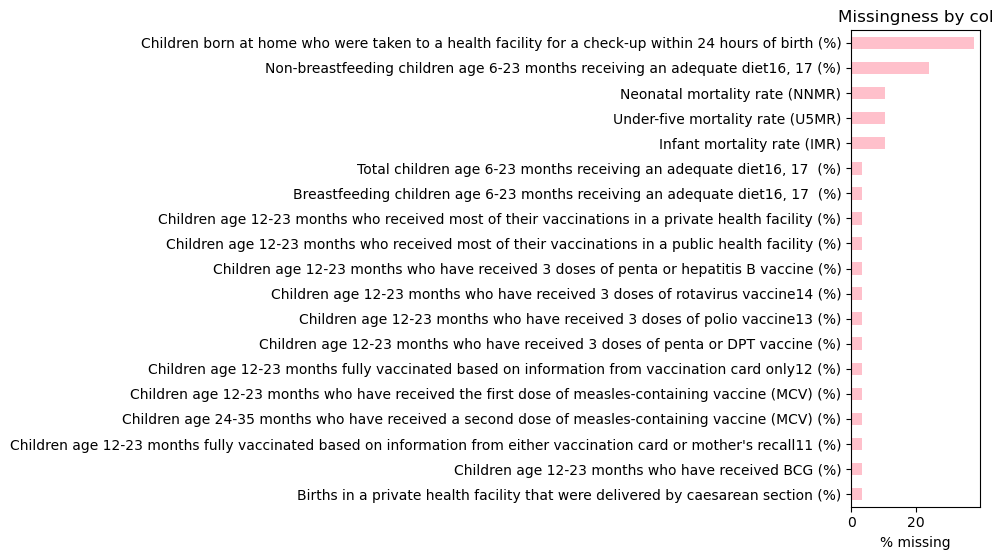

In [159]:
# visualizing

missing_cols = missing_summary.index.to_list()

fig, ax = plt.subplots(figsize=(10, max(4, 0.3*len(missing_cols))))
missing_summary["pct_missing"].sort_values().plot.barh(ax=ax, color = 'pink')
ax.set_xlabel("% missing")
ax.set_title("Missingness by col")

plt.tight_layout()
plt.show()

## Missingness Patterns

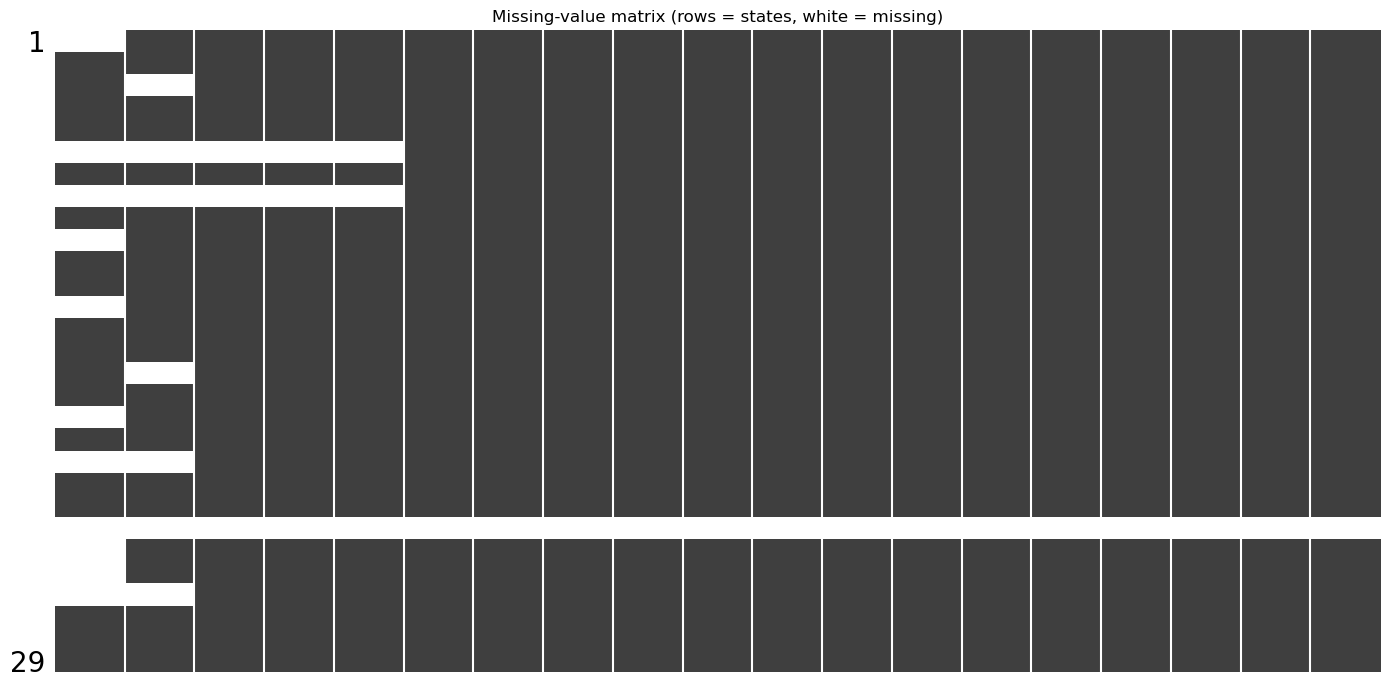

In [160]:
fig, ax = plt.subplots(figsize=(14,7))
msno.matrix(df[missing_cols], ax=ax, sparkline=False, labels=False)
ax.set_title("Missing-value matrix (rows = states, white = missing)")
plt.tight_layout()
plt.show()

In [161]:
# Rows where a State has any missing value, for context
df.loc[df[missing_cols].isna().any(axis=1), ["State"] + missing_cols].style.highlight_null(color="salmon")


,State,Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%),"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)",Neonatal mortality rate (NNMR),Under-five mortality rate (U5MR),Infant mortality rate (IMR),Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall11 (%),Births in a private health facility that were delivered by caesarean section (%),Children age 12-23 months who have received BCG (%),Children age 12-23 months who have received 3 doses of polio vaccine13 (%),Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),Children age 12-23 months fully vaccinated based on information from vaccination card only12 (%),Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),Children age 24-35 months who have received a second dose of measles-containing vaccine (MCV) (%),Children age 12-23 months who have received 3 doses of penta or hepatitis B vaccine (%),Children age 12-23 months who have received 3 doses of rotavirus vaccine14 (%),Children age 12-23 months who received most of their vaccinations in a public health facility (%),Children age 12-23 months who received most of their vaccinations in a private health facility (%),"Breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%)","Total children age 6-23 months receiving an adequate diet16, 17 (%)"
0,Andhra Pradesh,nan,19.500000,14.400000,33.700000,29.800000,69.300000,66.100000,92.400000,70.600000,84.800000,89.100000,83.700000,27.100000,83.000000,72.000000,86.400000,11.500000,15.200000,16.700000
2,Assam,2.800000,nan,15.200000,33.000000,22.700000,63.200000,78.800000,92.600000,69.300000,79.700000,70.600000,77.300000,12.500000,72.700000,44.800000,88.400000,9.200000,8.300000,7.900000
5,Goa,nan,nan,nan,nan,nan,77.900000,46.600000,96.500000,83.800000,89.300000,87.700000,92.900000,23.200000,95.200000,2.300000,90.800000,9.200000,18.900000,21.100000
7,Haryana,nan,nan,nan,nan,nan,94.100000,46.700000,97.700000,95.400000,94.100000,100.000000,96.400000,30.600000,94.100000,73.400000,93.600000,5.100000,15.100000,14.400000
9,Jammu and Kashmir,nan,15.000000,7.500000,15.700000,14.700000,83.000000,91.000000,91.000000,83.000000,90.000000,99.800000,88.700000,36.500000,88.000000,4.000000,98.800000,1.200000,11.900000,12.300000
12,Kerala,nan,14.300000,2.600000,3.900000,3.500000,77.600000,39.400000,98.200000,85.800000,86.100000,83.300000,86.400000,16.900000,85.300000,10.000000,83.900000,16.100000,22.200000,21.500000
15,Manipur,0.000000,nan,5.700000,17.100000,12.200000,75.100000,57.800000,95.200000,80.700000,87.800000,79.600000,83.700000,18.100000,87.500000,9.600000,88.600000,11.400000,19.600000,20.000000
17,Mizoram,nan,13.900000,14.400000,21.800000,20.600000,69.600000,30.700000,81.500000,73.900000,81.600000,82.200000,79.900000,35.000000,74.600000,14.400000,94.800000,5.200000,16.200000,15.900000
19,Odisha,nan,nan,24.600000,32.000000,31.200000,92.000000,68.600000,98.200000,92.600000,98.400000,93.400000,97.700000,39.200000,98.400000,90.600000,91.800000,6.800000,14.000000,14.700000
22,Sikkim,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


## MAR Test
If several columns go missing together for the same erows, that's a clue for MAR/MNAR mechanism.

/tmp/ipykernel_20953/3639426966.py:4: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


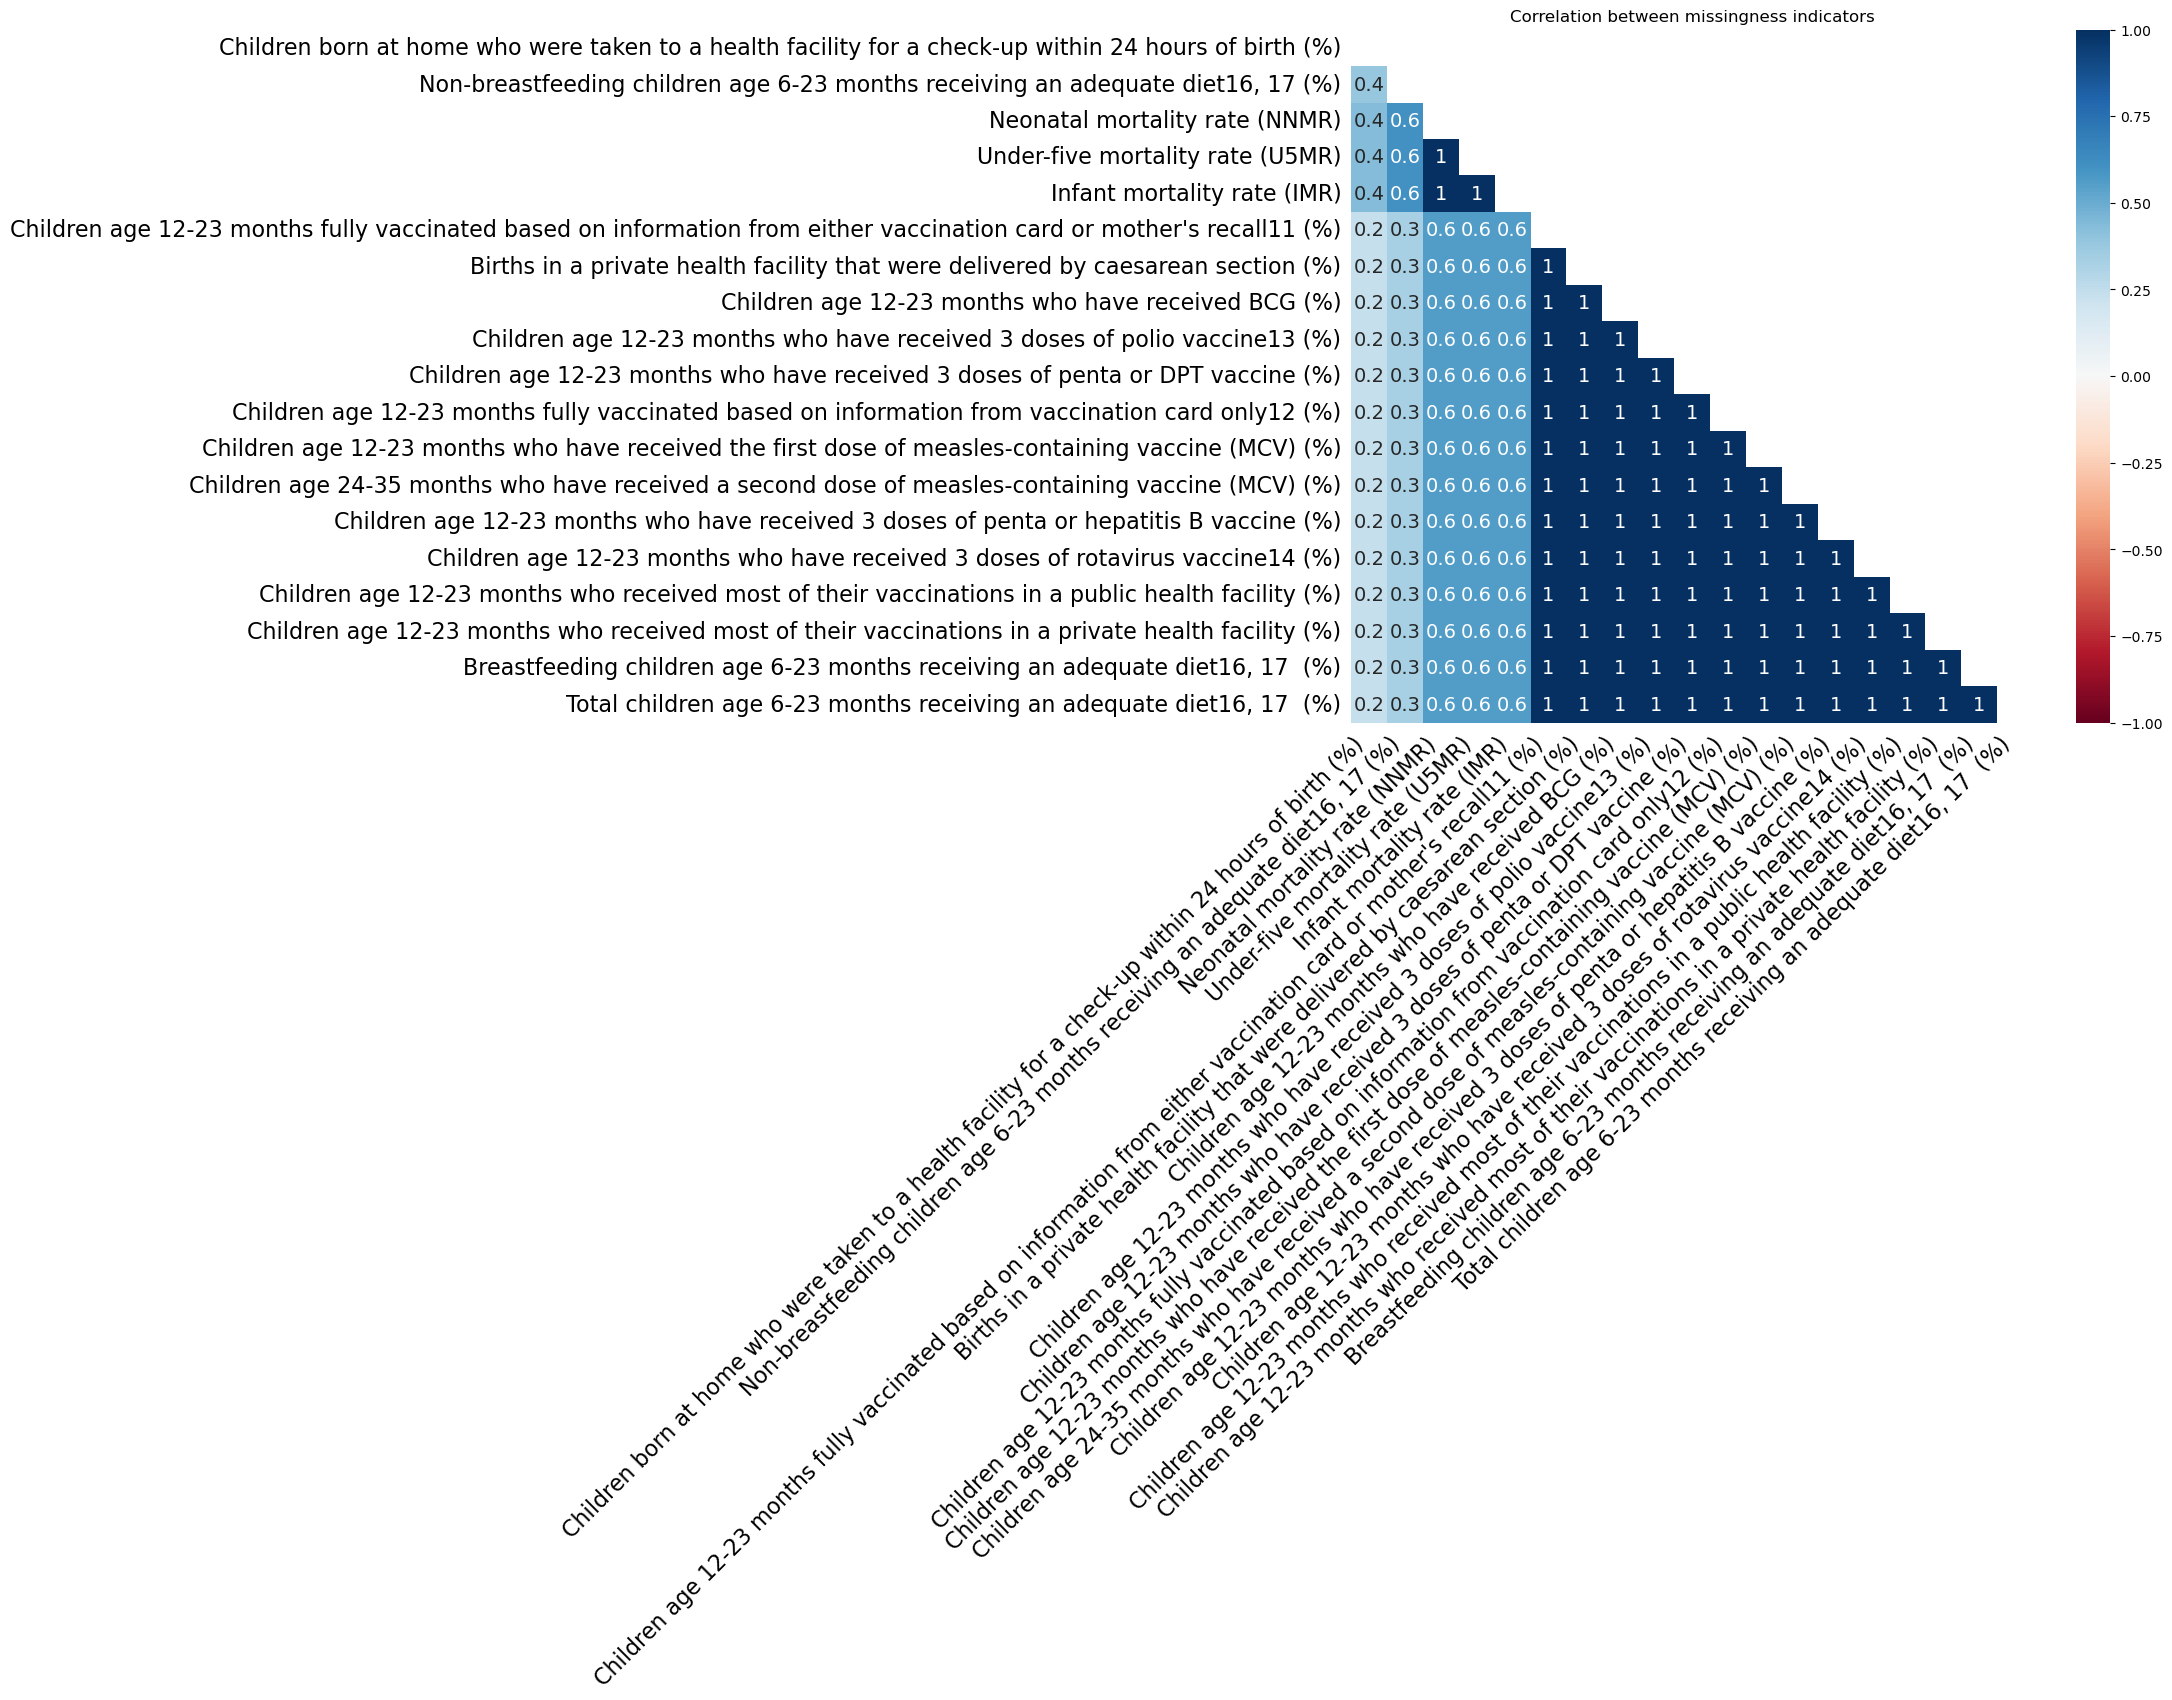

In [162]:
fig, ax = plt.subplots(figsize=(11, 9))
msno.heatmap(df[missing_cols], ax=ax, cmap="RdBu")
ax.set_title("Correlation between missingness indicators")
plt.tight_layout()
plt.show()

Allmost all child vaccination indicators share a correlation coefficient of 1. This most likely represents a survey section skip rule. 

Infant Mortality Rate and Under-Five Mortality Rate have 1.0 correlation with each other, while Neonatal Mortality Rate has 0.6 correlation from the same underlying birth-history module. 

Children born at home who were taken to a health facility - column shows low missingness correlation ($0.2\text{--}0.4$) with the rest of the variables. Missingness in this field is driven by a different, largely independent conditional condition (e.g., only applies to the subset of children who were specifically born at home).

## Testing the Missingness Mechanism
MCAR / MAR / MNAR

We test MCAR vs MAR through Little's MCAR test

### Little's MCAR test

In [163]:
numeric_cols = df.select_dtypes(include=["number"]).columns.to_list()
little_input = df[numeric_cols]

little_p = MCARTest(method="little").little_mcar_test(little_input)
print(f"Little's MCAR test p-value: {little_p:.4f}")

alpha = 0.05
if little_p > alpha:
    print(f"p = {little_p:.3f} > {alpha} -> fail to reject H0: data are consistent with MCAR "
          f"(globally).")
else:
    print(f"p = {little_p:.3f} <= {alpha} -> reject H0: missingness is NOT completely random")


Little's MCAR test p-value: 1.0000
p = 1.000 > 0.05 -> fail to reject H0: data are consistent with MCAR (globally).


The test gave a p-value of 1.00, which is well above the conventional significance threshold of 0.05. We therefore fail to reject the null hypothesis of Little’s test, meaning the pattern of missing values in this dataset is statistically consistent with being Missing Completely At Random (MCAR). This supports using simple, unconditional imputation methods (e.g., mean/median imputation) rather than model-based methods that assume a MAR mechanism, since there is no statistical evidence that missingness is being driven by other variables in the data.

Limitations :

Very small sample size and so, Little’s test has very low statistical power. \
Little’s test gives one overall p-value for the whole dataset; it cannot tell us whether a specific column’s missingness is random.

## Outliers

### IQR method

In [164]:
def iqr_outlier_report(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (s < lo) | (s > hi)
        if mask.sum() > 0:
            rows.append({
                "column": c,
                "n_outliers": int(mask.sum()),
                "lower_bound": round(lo, 2),
                "upper_bound": round(hi, 2),
                "outlier_states": data.loc[s[mask].index, "State"].tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

iqr_report = iqr_outlier_report(df, numeric_cols)
iqr_report


,column,n_outliers,lower_bound,upper_bound,outlier_states
1,Neonatal mortality rate (NNMR),4,5.55,2.655000e+01,"[Bihar, Kerala, Uttarkhand, Uttar Pradesh]"
6,Children who received postnatal care from a do...,4,60.95,1.093500e+02,"[Meghalaya, Mizoram, Nagaland, Sikkim]"
22,Per_Capita_Health_Exp_Accounts,4,-866.85,4.138560e+03,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
19,Children under 5 years who are overweight (wei...,4,0.50,8.500000e+00,"[Arunachal Pradesh, Jammu and Kashmir, Mizoram..."
3,Under-five mortality rate (U5MR),3,7.32,4.813000e+01,"[Bihar, Kerala, Uttar Pradesh]"
15,Breastfeeding children age 6-23 months receivi...,3,-0.67,2.512000e+01,"[Arunachal Pradesh, Meghalaya, West Bengal]"
9,Births attended by skilled health personnel10 (%),3,86.30,1.031000e+02,"[Bihar, Meghalaya, Nagaland]"
2,Infant mortality rate (IMR),3,8.56,3.966000e+01,"[Bihar, Kerala, Uttar Pradesh]"
20,Women age 15 years and above who use any kind ...,3,-15.00,3.140000e+01,"[Manipur, Mizoram, Tripura]"
24,Per_Capita_Health_Exp_RE,3,-1430.71,5.108100e+03,"[Arunachal Pradesh, Goa, Sikkim]"


### Z-score method

In [165]:
def zscore_outlier_report(data, cols, threshold=3.0):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if s.std(ddof=0) == 0 or s.empty:
            continue
        z = (s - s.mean()) / s.std(ddof=0)
        mask = z.abs() > threshold
        if mask.sum() > 0:
            rows.append({
                "column": c,
                "n_outliers": int(mask.sum()),
                "outlier_states": data.loc[s[mask].index, "State"].tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

z_report = zscore_outlier_report(df, numeric_cols)
z_report


,column,n_outliers,outlier_states
12,Women age 15 years and above who consume alcoh...,2,"[Arunachal Pradesh, Sikkim]"
0,Population (Total),1,[Uttar Pradesh]
2,Children who received postnatal care from a do...,1,[Mizoram]
3,Institutional births (%),1,[Nagaland]
4,Home births that were conducted by skilled hea...,1,[Nagaland]
1,Average out-of-pocket expenditure per delivery...,1,[Manipur]
5,Births attended by skilled health personnel10 (%),1,[Nagaland]
6,Children age 12-23 months who have received BC...,1,[Mizoram]
8,Breastfeeding children age 6-23 months receivi...,1,[Meghalaya]
7,Children age 12-23 months who have received 3 ...,1,[Meghalaya]


### Box-plot for headline variables

different mortality rates, expenditure measures

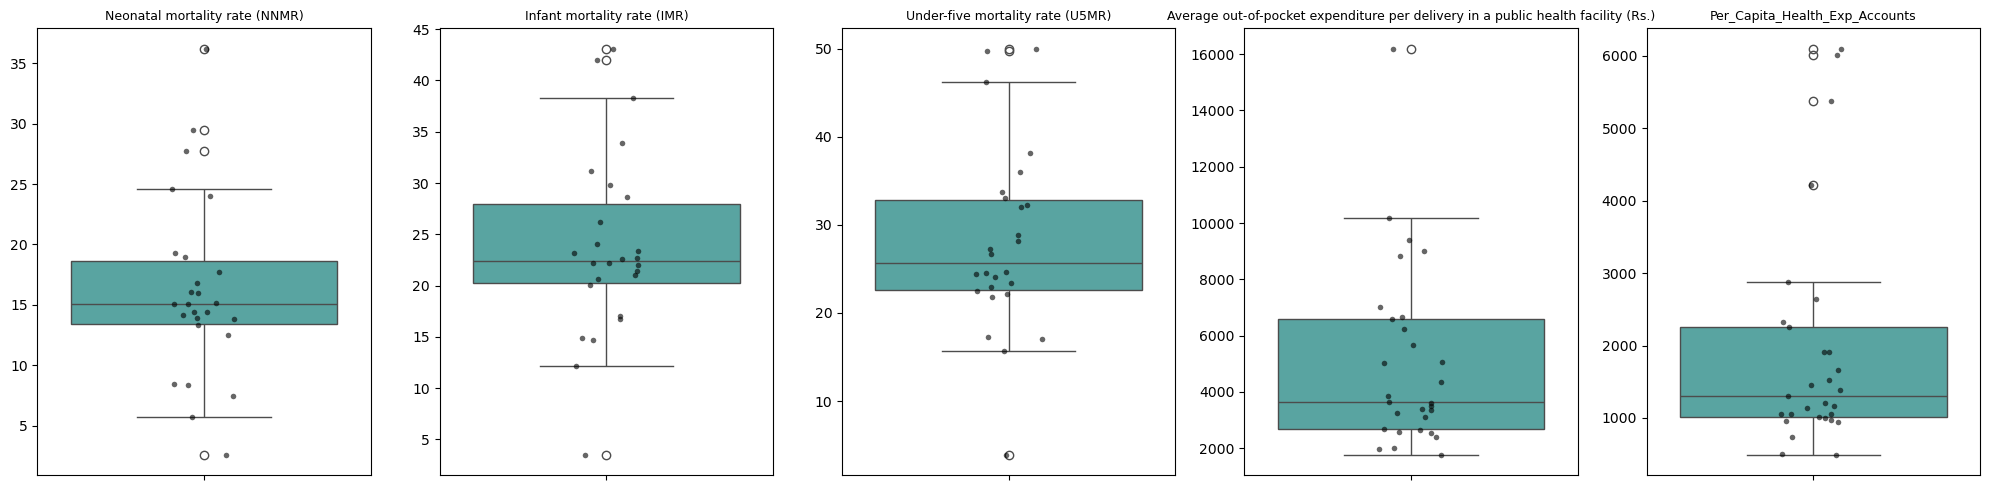

In [166]:
key_vars = ["Neonatal mortality rate (NNMR)","Infant mortality rate (IMR)","Under-five mortality rate (U5MR)",
    "Average out-of-pocket expenditure per delivery in a public health facility (Rs.)","Per_Capita_Health_Exp_Accounts"]

fig, axes = plt.subplots(1, len(key_vars), figsize=(4 * len(key_vars), 5))
for ax, col in zip(axes, key_vars):
    sns.boxplot(y=df[col], ax=ax, color="#4CB0AD")
    sns.stripplot(y=df[col], ax=ax, color="black", size=4, alpha=0.6, jitter=0.1)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


Given the small sample 29 states and that all flagged outliers are not extremely variable, I am going to keep it as it is

## Imputation

Little's MCAR test gave p = 1.00 (globally consistent with MCAR), with no column-specific evidence that missingness depends on other observed variables. We therefore do not have statistical grounds to treat columns differently, and so we apply a single, simple imputation method uniformly across all missing columns: median imputation.

In [167]:
df_clean = df.copy()

median_imputer = SimpleImputer(strategy="median")
df_clean[missing_cols] = median_imputer.fit_transform(df_clean[missing_cols])

print("Remaining missing values:", df_clean[numeric_cols].isna().sum().sum())

Remaining missing values: 0


## Before and After Check

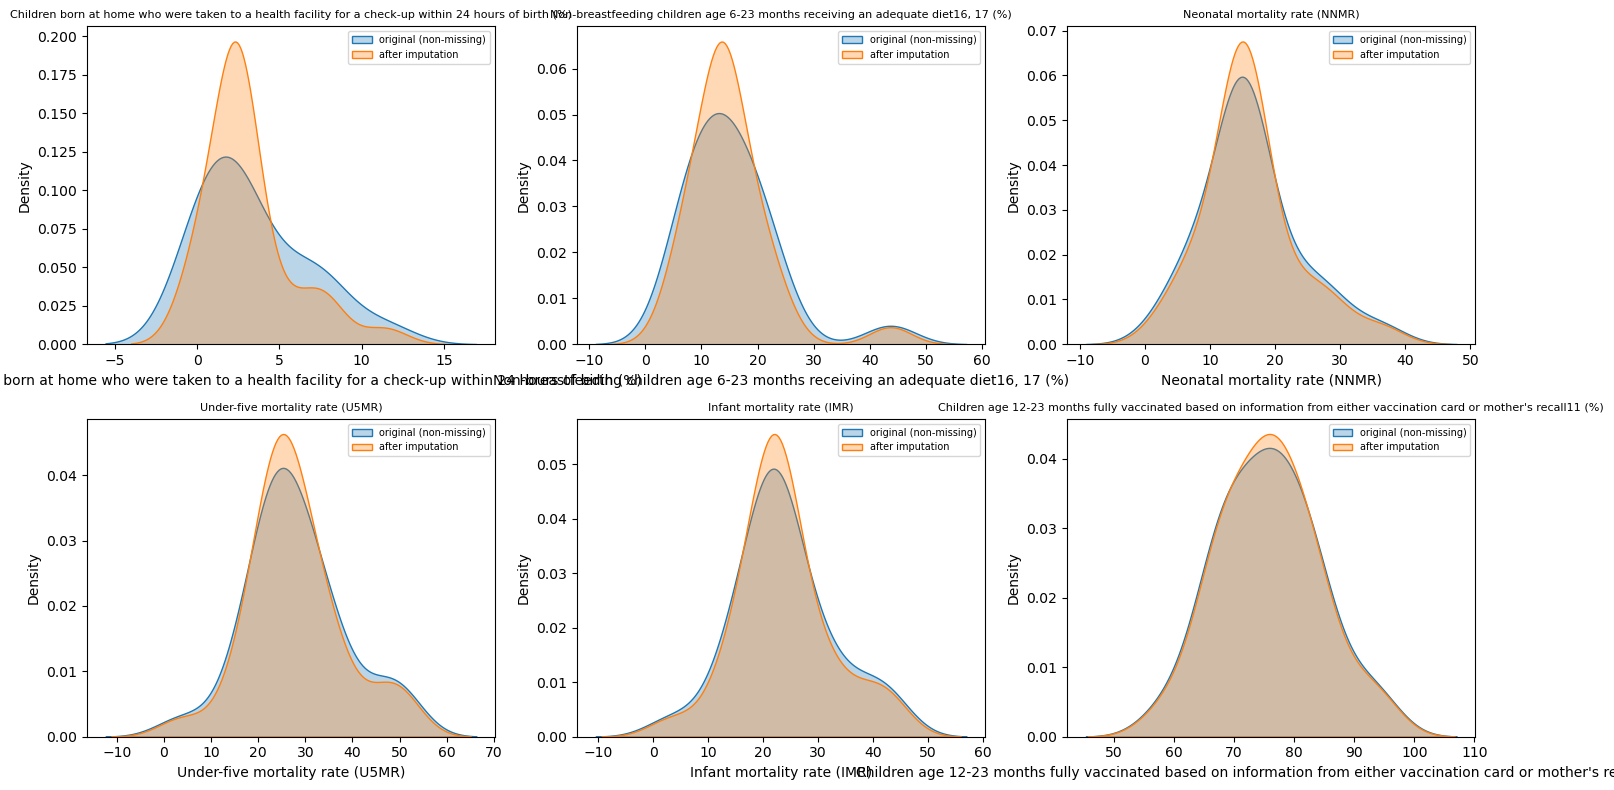

In [168]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
check_cols = missing_cols[:6]
for ax, c in zip(axes.flat, check_cols):
    sns.kdeplot(df[c].dropna(), ax=ax, label="original (non-missing)", fill=True, alpha=0.3)
    sns.kdeplot(df_clean[c], ax=ax, label="after imputation", fill=True, alpha=0.3)
    ax.set_title(c, fontsize=8)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [169]:
missing_after = df_clean.isna().sum()
assert missing_after.sum() == 0, "Missing values remain after imputation!"
print("All missing values resolved. Final shape:", df_clean.shape)
df_clean.head()

All missing values resolved. Final shape: (29, 50)


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Neonatal mortality rate (NNMR),Infant mortality rate (IMR),Under-five mortality rate (U5MR),Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),Average out-of-pocket expenditure per delivery in a public health facility (Rs.),...,Men whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2) (%),Women who are overweight or obese (BMI ≥25.0 kg/m2)21 (%),Men who are overweight or obese (BMI ≥25.0 kg/m2) (%),Women age 15 years and above who use any kind of tobacco (%),Men age 15 years and above who use any kind of tobacco (%),Women age 15 years and above who consume alcohol (%),Men age 15 years and above who consume alcohol (%),Per_Capita_Health_Exp_Accounts,Per_Capita_Health_Exp_BE,Per_Capita_Health_Exp_RE
0,Andhra Pradesh,52504000.0,525929.6,605549.45,526323.02,14.4,29.8,33.7,92.2,2659,...,15.0,44.4,37.7,1.9,15.8,0.3,20.5,1001.694347,1153.339650,1002.443661
1,Arunachal Pradesh,1519000.0,92615.0,131266.59,91612.20,12.5,16.7,22.2,67.0,10178,...,6.4,28.9,32.4,14.0,44.5,14.9,44.3,6097.103357,8641.645161,6031.086241
2,Assam,34668000.0,451977.3,591193.62,633180.84,15.2,22.7,33.0,76.8,6651,...,11.3,23.8,25.4,16.2,43.9,2.6,21.3,1303.730530,1705.300623,1826.412946
3,Bihar,121302000.0,611797.7,638425.20,724500.80,29.5,43.1,50.0,62.6,3511,...,12.9,25.2,18.7,3.6,40.3,0.5,14.0,504.359120,526.310531,597.270284
4,Chattisgarh,29109000.0,404904.7,403411.10,442702.30,19.3,26.2,28.9,90.3,2536,...,11.1,23.1,22.4,9.4,33.4,1.3,28.6,1390.994881,1385.863822,1520.843382


## Saving the Cleaned df

In [170]:
OUT_PATH = "budget_nfhs_states_clean.csv"
df_clean.to_csv(OUT_PATH, index=False)
print(f"Saved cleaned data to {OUT_PATH}")

Saved cleaned data to budget_nfhs_states_clean.csv
